# TP 1 : Préparation et Exploration de la Télémétrie d'un Atelier d'Usinage Connecté

**Ressource :** R3.13 - Maintenance Prédictive & Data Science  
**Séance 1 :** Introduction & préparation des données de télémétrie  
**Rôle :** Ingénieur Data Science & Machine Learning  
**Reproductibilité :** Fixation systématique de la graine aléatoire (`seed = 42`)

---

## Contexte Industriel & Alignement Pédagogique

Un atelier de fabrication mécanique moderne comprend **6 machines-outils à commande numérique (M-01 à M-06)** monitorées en continu par des capteurs IoT échantillonnant toutes les 5 minutes. Les données couvrent une journée de production continue (24h) découpée en 3 équipes de travail (*matin, après-midi, nuit*).

Dans ce premier TP, nous établissons un pipeline de prétraitement rigoureux et conforme aux conventions méthodologiques du cours :
- Audit qualité et classification des variables (distinction descripteurs vs vérité terrain/alarmes).
- Découpage chronologique par quantile temporel sans fuite d'information (*data leakage*).
- Imputation médiane robuste aux valeurs aberrantes (outliers capteurs).
- Encodage catégoriel rigoureux (`OneHotEncoder` sans ordre artificiel et `OrdinalEncoder` respectant la hiérarchie physique de charge).
- Standardisation sans fuite et interprétation physique de la dérive thermique diurne.
- Analyse géométrique des distances (euclidienne, Manhattan, cosinus) et mise en évidence mathématique de l'effet d'échelle.


## 0. Configuration de l'Environnement & Imports

Nous importons les modules scientifiques standards et fixons la graine aléatoire globale (`SEED = 42`).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

# Fonctions de distances spatiales Scipy
from scipy.spatial.distance import euclidean, cityblock, cosine

# Reproductibilité stricte
SEED = 42
np.random.seed(SEED)

# Configuration esthétique Seaborn & Matplotlib
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 100
})

# Paramètres Pandas
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

print(" Environnement configuré et reproductible (seed = 42).")


 Environnement configuré et reproductible (seed = 42).


---
## 1. Premier Regard & Classification des Variables

### 1.1 Chargement des données et inspection initiale
Nous chargeons le fichier de télémétrie `atelier_connecte.csv` et inspectons sa dimension, ses types de données et ses statistiques descriptives.


In [ ]:
# Chargement du dataset
data_path = Path("../data/atelier_connecte.csv")
if not data_path.exists():
    data_path = Path("data/atelier_connecte.csv")

df = pd.read_csv(data_path)

print("=" * 60)
print(f"Dimensions du jeu de données (lignes, colonnes) : {df.shape}")
print("=" * 60)
df.head()


Dimensions du jeu de données (lignes, colonnes) : (1728, 20)


,horodatage,machine_id,equipe,niveau_charge,temperature,vibration,courant,cadence,vibration_pic,vib_f1,vib_f2,vib_f3,vib_f4,defaut,alarme_temperature,alarme_vibration,alarme_courant,alarme_cadence,regime_reference,donnees_synthetiques
0,2025-01-06T00:00:00,M-01,nuit,moyen,72.920,NaN,15.647,43.537,6.326,1.775,1.238,0.747,0.304,1,0,0,0,0,incident_thermique,True
1,2025-01-06T00:00:00,M-02,nuit,faible,79.614,4.364,14.667,45.833,6.782,2.024,1.344,0.761,0.333,0,0,1,0,0,incident_roulement,True
2,2025-01-06T00:00:00,M-03,nuit,moyen,83.296,5.586,19.129,40.156,9.458,2.944,1.641,0.920,0.412,1,1,1,1,0,incident_roulement,True
3,2025-01-06T00:00:00,M-04,nuit,faible,83.680,5.411,19.626,36.881,9.223,2.093,1.728,0.993,0.511,1,1,1,1,1,incident_roulement,True
4,2025-01-06T00:00:00,M-05,nuit,faible,79.495,4.701,16.808,37.720,7.607,1.864,1.337,0.807,0.564,1,0,1,0,1,incident_roulement,True


In [3]:
# Structure et types de données
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   horodatage            1728 non-null   str    
 1   machine_id            1728 non-null   str    
 2   equipe                1728 non-null   str    
 3   niveau_charge         1728 non-null   str    
 4   temperature           1669 non-null   float64
 5   vibration             1641 non-null   float64
 6   courant               1681 non-null   float64
 7   cadence               1685 non-null   float64
 8   vibration_pic         1728 non-null   float64
 9   vib_f1                1728 non-null   float64
 10  vib_f2                1728 non-null   float64
 11  vib_f3                1728 non-null   float64
 12  vib_f4                1728 non-null   float64
 13  defaut                1728 non-null   int64  
 14  alarme_temperature    1728 non-null   int64  
 15  alarme_vibration      1728 non-n

In [4]:
# Statistiques descriptives initiales
df.describe().T


,count,mean,std,min,25%,50%,75%,max
temperature,1669.000,77.618,6.217,62.570,72.769,77.238,81.923,98.036
vibration,1641.000,2.870,1.250,0.477,1.872,2.727,3.651,7.298
courant,1681.000,14.501,2.723,8.415,12.268,14.445,16.462,23.878
cadence,1685.000,49.204,7.036,25.947,44.201,49.293,54.610,66.983
vibration_pic,1728.000,4.717,2.083,0.809,3.049,4.479,6.014,12.471
vib_f1,1728.000,1.206,0.559,0.188,0.755,1.127,1.548,3.596
vib_f2,1728.000,0.883,0.403,0.176,0.560,0.825,1.120,2.596
vib_f3,1728.000,0.513,0.242,0.065,0.325,0.474,0.649,1.978
vib_f4,1728.000,0.258,0.132,0.050,0.159,0.232,0.333,0.995
defaut,1728.000,0.095,0.293,0.000,0.000,0.000,0.000,1.000


### 1.2 Classification des 20 colonnes dans les 7 catégories

Le jeu de données comporte 20 colonnes réparties selon leurs caractéristiques fonctionnelles :

| N° | Catégorie du cours | Nb | Variables concernées | Description & Rôle métier |
| :---: | :--- | :---: | :--- | :--- |
| **1** | **Mesures de procédé** | 4 | `temperature`, `vibration`, `courant`, `cadence` | Paramètres physiques continus de coupe. Soumis à 3-5% de pertes de télémétrie. |
| **2** | **Spectre vibratoire** | 5 | `vibration_pic`, `vib_f1`, `vib_f2`, `vib_f3`, `vib_f4` | Indicateurs fréquentiels fins de vibration mécanique (crête et harmoniques). |
| **3** | **Catégories** | 3 | `machine_id`, `equipe`, `niveau_charge` | Variables qualitatives (machines, postes de travail, niveau de charge demandé). |
| **4** | **Alarmes** | 4 | `alarme_temperature`, `alarme_vibration`, `alarme_courant`, `alarme_cadence` | Seuils binaires automatisés (0/1) calculés par les automates industriels. |
| **5** | **Défaut** | 1 | `defaut` | Étiquette binaire constatée a posteriori lors du contrôle qualité ou arrêt machine. |
| **6** | **Référence expert** | 1 | `regime_reference` | Diagnostic expert a posteriori (`nominal`, `charge_elevee`, `usure_avancee`, `incident_thermique`, `incident_roulement`). |
| **7** | **Autres** | 2 | `horodatage`, `donnees_synthetiques` | Marqueur temporel (timestamp ISO 8601) et drapeau technique constant (`True`). |

### 1.3 Exclusion motivée des variables pour la segmentation non supervisée (TP 2)

En **apprentissage non supervisé (clustering)**, il n'existe par définition **aucune variable cible (*target*)**. L'algorithme a pour seule mission de découvrir la structure géométrique intrinsèque des données. Par conséquent :

1. **`defaut` et `regime_reference` (Vérités terrain / Cibles a posteriori) :**
   - *Motif :* Ce sont des annotations a posteriori. Les intégrer dans les variables d'entrée constituerait une **fuite de données / cible majeure (*target leakage*)**. Elles doivent être **strictement réservées à l'évaluation a posteriori** de la pertinence des clusters (pureté, Indice de Rand Ajusté - ARI, score silhouette vs régimes réels).
2. **`alarme_*` (Seuils binaires dérivés et colinéaires) :**
   - *Motif :* Les alarmes sont de simples fonctions indicatrices directes des mesures continues (ex. `temp > 83 °C`). Les injecter dans le modèle créerait une redondance colinéaire artificielle et plaquerait des discontinuités binaires arbitraires qui masqueraient la dynamique continue sous-jacente des machines.
3. **`horodatage` (Identifiant temporel) :**
   - *Motif :* L'horodatage indique l'instant chronologique du relevé, et non l'état de santé physique de la machine. L'inclure conduirait le modèle à segmenter sur l'heure de la journée plutôt que sur les anomalies mécaniques.
4. **`donnees_synthetiques` (Constante inutile) :**
   - *Motif :* Colonne constante (100% de `True`, variance nulle) n'apportant aucun pouvoir séparateur.


In [5]:
# Définition formelle des groupes de colonnes
COLS_PROCEDE = ["temperature", "vibration", "courant", "cadence"]
COLS_SPECTRE = ["vibration_pic", "vib_f1", "vib_f2", "vib_f3", "vib_f4"]
COLS_CATEGORIES = ["machine_id", "equipe", "niveau_charge"]
COLS_ALARMES = ["alarme_temperature", "alarme_vibration", "alarme_courant", "alarme_cadence"]
COL_DEFAUT = ["defaut"]
COL_EXPERT = ["regime_reference"]
COLS_AUTRES = ["horodatage", "donnees_synthetiques"]

TOUTES_COLONNES = COLS_PROCEDE + COLS_SPECTRE + COLS_CATEGORIES + COLS_ALARMES + COL_DEFAUT + COL_EXPERT + COLS_AUTRES
assert len(TOUTES_COLONNES) == 20, "Erreur : le dataset doit contenir exactement 20 colonnes."
print(f"Classification validée : {len(TOUTES_COLONNES)} colonnes classées.")


Classification validée : 20 colonnes classées.


---
## 2. Audit des Valeurs Manquantes (Pertes de Télémétrie)

Dans les environnements industriels connectés, les coupures de réseau IoT et les micro-interférences entraînent des pertes de trames de télémétrie. Nous quantifions ces manques par variable et par machine.


In [6]:
# Pourcentage de valeurs manquantes par colonne
nan_par_col = pd.DataFrame({
    "Nb_Manquants": df.isna().sum(),
    "Taux_Manquants_%": (df.isna().mean() * 100)
}).sort_values(by="Taux_Manquants_%", ascending=False)

print("Variables présentant des valeurs manquantes :")
nan_par_col[nan_par_col["Nb_Manquants"] > 0]


Variables présentant des valeurs manquantes :


,Nb_Manquants,Taux_Manquants_%
vibration,87,5.035
temperature,59,3.414
courant,47,2.720
cadence,43,2.488


In [7]:
# Pourcentage de valeurs manquantes groupé par machine_id
nan_par_machine = df.groupby("machine_id")[COLS_PROCEDE].apply(lambda g: (g.isna().mean() * 100))
print("Taux de valeurs manquantes (%) par machine :")
nan_par_machine


Taux de valeurs manquantes (%) par machine :


,temperature,vibration,courant,cadence
machine_id,,,,
M-01,3.819,6.597,2.083,2.431
M-02,4.861,5.556,1.736,2.778
M-03,2.431,3.125,3.472,3.125
M-04,3.819,5.208,3.472,2.431
M-05,2.778,5.208,2.778,2.083
M-06,2.778,4.514,2.778,2.083


C:\Users\reval\AppData\Local\Temp\ipykernel_21480\3457856649.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cols_avec_nan, y=nan_par_col.loc[cols_avec_nan, "Taux_Manquants_%"], ax=axes[0], palette="Blues_r")


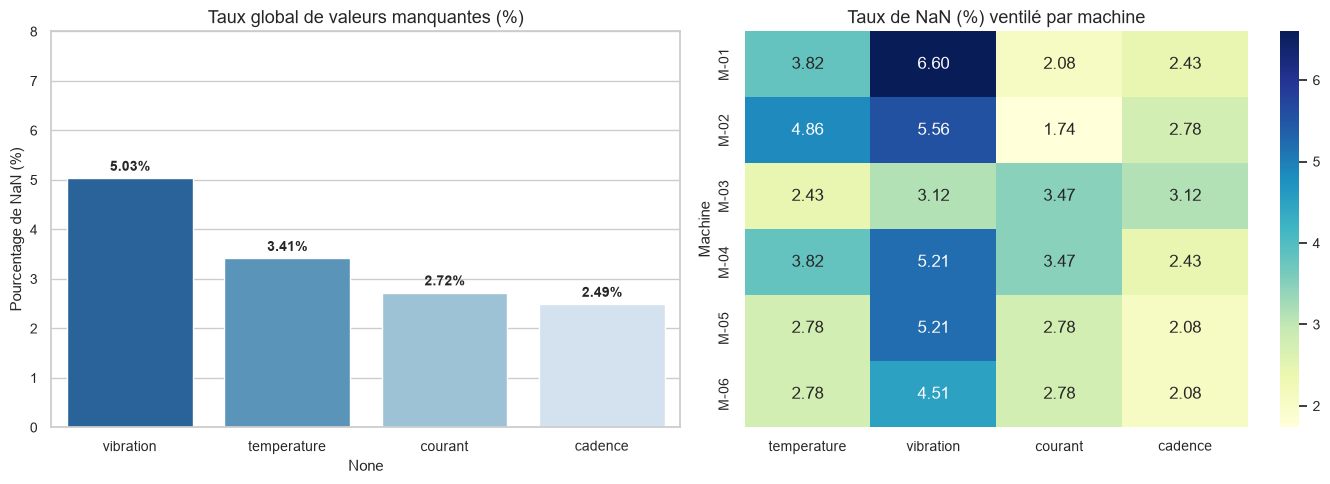

In [8]:
# Visualisation graphique de la répartition des trous
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Taux par mesure de procédé
cols_avec_nan = nan_par_col[nan_par_col["Nb_Manquants"] > 0].index
sns.barplot(x=cols_avec_nan, y=nan_par_col.loc[cols_avec_nan, "Taux_Manquants_%"], ax=axes[0], palette="Blues_r")
axes[0].set_title("Taux global de valeurs manquantes (%)")
axes[0].set_ylabel("Pourcentage de NaN (%)")
axes[0].set_ylim(0, 8)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.15),
                     ha="center", fontsize=10, weight="bold")

# Graphique 2 : Heatmap par machine
sns.heatmap(nan_par_machine, annot=True, fmt=".2f", cmap="YlGnBu", cbar=True, ax=axes[1])
axes[1].set_title("Taux de NaN (%) ventilé par machine")
axes[1].set_ylabel("Machine")

plt.tight_layout()
plt.show()


### 2.1 Conclusion sur la Répartition des Trous de Télémétrie

- **Variables touchées :** Les manques se cantonnent exclusivement aux **4 mesures de procédé** (`temperature`, `vibration`, `courant`, `cadence`) avec des taux compris entre **2.5% et 5.0%**.
- **Répartition inter-machines :** La heatmap confirme que les trous ne sont **pas concentrés sur une machine particulière** (qui aurait un capteur physiquement défaillant), mais sont distribués de façon homogène sur les 6 machines (`M-01` à `M-06`).
- **Nature statistique :** Il s'agit d'un mécanisme **MCAR** (*Missing Completely At Random*) provoqué par des pertes aléatoires de paquets lors de la transmission radio, justifiant pleinement une imputation statistique globale.


---
## 3. Exploration des Distributions Statistiques & Hypothèses de Maintenance

Nous analysons les distributions empiriques des capteurs critiques pour identifier les anomalies physiques et formuler nos hypothèses métier.


C:\Users\reval\AppData\Local\Temp\ipykernel_21480\116059256.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="machine_id", y="vibration", palette="Set2", ax=axes[2])


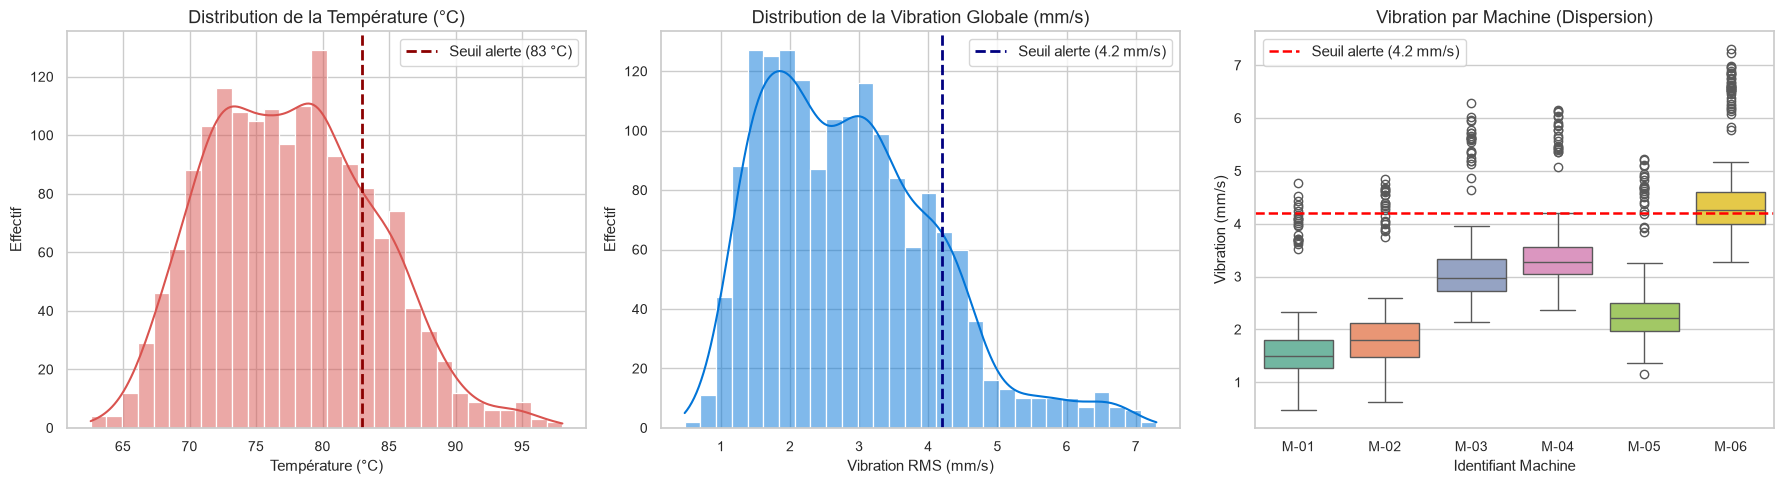

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogramme de la température
sns.histplot(df["temperature"].dropna(), kde=True, color="#d9534f", ax=axes[0], bins=30)
axes[0].axvline(83.0, color="darkred", linestyle="--", linewidth=2, label="Seuil alerte (83 °C)")
axes[0].set_title("Distribution de la Température (°C)")
axes[0].set_xlabel("Température (°C)")
axes[0].set_ylabel("Effectif")
axes[0].legend()

# 2. Histogramme de la vibration
sns.histplot(df["vibration"].dropna(), kde=True, color="#0275d8", ax=axes[1], bins=30)
axes[1].axvline(4.2, color="navy", linestyle="--", linewidth=2, label="Seuil alerte (4.2 mm/s)")
axes[1].set_title("Distribution de la Vibration Globale (mm/s)")
axes[1].set_xlabel("Vibration RMS (mm/s)")
axes[1].set_ylabel("Effectif")
axes[1].legend()

# 3. Boxplot de la vibration par machine
sns.boxplot(data=df, x="machine_id", y="vibration", palette="Set2", ax=axes[2])
axes[2].axhline(4.2, color="red", linestyle="--", linewidth=1.8, label="Seuil alerte (4.2 mm/s)")
axes[2].set_title("Vibration par Machine (Dispersion)")
axes[2].set_xlabel("Identifiant Machine")
axes[2].set_ylabel("Vibration (mm/s)")
axes[2].legend()

plt.tight_layout()
plt.show()


In [10]:
# Profil moyen et dispersion par machine
profil_machines = df.groupby("machine_id")[["temperature", "vibration", "courant", "cadence", "vibration_pic"]].agg(["mean", "std"])
profil_machines.round(2)


temperature       vibration       courant       cadence       vibration_pic      
                  mean   std      mean   std    mean   std    mean   std          mean   std
machine_id                                                                                  
M-01            70.490 3.400     1.700 0.790  11.360 1.410  57.430 3.960         2.800 1.290
M-02            73.440 3.380     1.970 0.810  12.550 1.360  54.280 3.730         3.220 1.300
M-03            79.270 3.490     3.180 0.800  15.440 1.510  47.360 3.770         5.240 1.390
M-04            81.320 3.470     3.440 0.740  16.200 1.420  44.510 4.070         5.690 1.330
M-05            75.220 3.440     2.380 0.780  13.410 1.470  51.290 4.140         3.940 1.350
M-06            85.830 3.880     4.510 0.890  18.100 1.580  40.370 4.250         7.410 1.480

### 3.1 Analyse Visuelle des Graphiques

1. **Température (°C) :**
   - La distribution s'étale de 62 °C à plus de 95 °C. Elle montre une queue droite étirée et de multiples dépassements du seuil d'alarme (83 °C).
2. **Vibration (mm/s) :**
   - La distribution globale présente une forte asymétrie droite (*positive skew*) : la grande majorité des relevés est groupée entre 1.0 et 3.0 mm/s, mais une traîne importante atteint 7.5 - 8.0 mm/s.
3. **Disparités entre machines (Boxplot) :**
   - **`M-01` et `M-02` :** Machines de référence parfaitement saines. Médiane vibratoire basse (~1.3 à 1.7 mm/s), variabilité très resserrée, aucun dépassement d'alarme.
   - **`M-03`, `M-04`, `M-05` :** Niveau d'usure modéré et stable.
   - **`M-06` :** Machine en avarie mécanique sévère. Sa médiane vibratoire dépasse déjà 4.0 mm/s et plus de la moitié de ses relevés franchissent le seuil critique d'alarme (4.2 mm/s), avec des valeurs de crête extrêmes.

---

### 3.2 Formulation de Deux Hypothèses de Maintenance (à tester aux TP 2 et 3)

* 🔍 **Hypothèse 1 (État critique et avarie mécanique sur la machine M-06) :**  
  La machine **`M-06`** présente un niveau de vibration moyen considérablement plus élevé ($> 4\text{ mm/s}$) et une température moyenne supérieure de plus de $15\,^\circ\text{C}$ à celle de `M-01`, révélant une dégradation mécanique avancée (ex: détérioration de roulement de broche ou jeu de guidage).  
  *Test futur (TP 2) :* L'algorithme de segmentation non supervisée (K-Means/DBSCAN) doit isoler spontanément les relevés de `M-06` dans un cluster d'incident/usure spécifique, sans jamais lui fournir l'identifiant machine.

* 🔍 **Hypothèse 2 (Dérive thermomécanique diurne et couplage charge-vibration) :**  
  L'atelier subit une élévation continue de température au fil des trois équipes de la journée (échauffement progressif des bâtis et de l'air ambiant) couplée aux augmentations de cadence/charge l'après-midi, ce qui augmente le courant moteur et la probabilité de déclenchement d'alarmes.  
  *Test futur (TP 3 & 4) :* Les modèles d'anomalies devront distinguer l'échauffement normal en charge élevée d'une véritable rupture mécanique nécessitant un arrêt d'urgence.


---
## 4. Découpage Chronologique sans Fuite du Futur (Train/Test Split)

### 4.1 Justification : Pourquoi un tirage aléatoire provoquerait du *Data Leakage* ?

Sur des séries temporelles de capteurs industriels, l'application d'un découpage aléatoire classique (`train_test_split(shuffle=True)`) provoque une **fuite de données du futur (*data leakage / look-ahead bias*)** :
1. **Autocorrélation temporelle :** Les mesures à $t$ et $t + 5\text{ min}$ sur une même machine sont fortement corrélées. Mélanger les instants placerait le passé et le futur d'une même machine à la fois dans le train et dans le test : le modèle apprendrait à "interpoler" localement l'état du capteur au lieu de prédire.
2. **Non-stationnarité physique :** En usinage, les bâtis chauffent et les outils s'usent au fil des heures. Si le modèle s'entraîne sur des relevés de l'après-midi pour prédire le matin, il viole la causalité temporelle.
3. **Condition opérationnelle réelle :** En usine, l'algorithme ne prédit jamais le passé à partir du futur ; il est calibré sur les données passées et appliqué au flux futur.

### 4.2 Application exacte de la méthode du cours (Quantile à 70% sur `horodatage`)

Pour découper proprement la timeline sans tronquer un pas de temps entre les 6 machines qui tournent simultanément, nous convertissons `horodatage` en `pd.to_datetime`, calculons le **quantile à 70%**, et découpons exactement selon la convention du cours :

```python
coupure = df["horodatage"].quantile(0.7)
train = df[df["horodatage"] <= coupure].copy()
test = df[df["horodatage"] > coupure].copy()
```


In [ ]:
# 1. Conversion de la colonne horodatage en datetime
df["horodatage"] = pd.to_datetime(df["horodatage"])

# 2. Tri chronologique rigoureux
df = df.sort_values(by=["horodatage", "machine_id"]).reset_index(drop=True)

# 3. Calcul de la date de coupure par le quantile 0.7
coupure = df["horodatage"].quantile(0.7)

# 4. Séparation Train (<= coupure) et Test (> coupure)
train = df[df["horodatage"] <= coupure].copy()
test = df[df["horodatage"] > coupure].copy()

print("=" * 60)
print(f"Horodatage de coupure (quantile 70%) : {coupure}")
print(f"Dimensions Train : {train.shape} ({len(train) / len(df) * 100:.1f} % du total)")
print(f"Dimensions Test  : {test.shape}  ({len(test) / len(df) * 100:.1f} % du total)")
print("=" * 60)

# Vérification de la parité entre machines
print("Nombre de relevés par machine dans le Train :")
print(train["machine_id"].value_counts().to_dict())
print("Nombre de relevés par machine dans le Test :")
print(test["machine_id"].value_counts().to_dict())


Horodatage de coupure (quantile 70%) : 2025-01-06 16:45:00
Dimensions Train : (1212, 20) (70.1 % du total)
Dimensions Test  : (516, 20)  (29.9 % du total)
Nombre de relevés par machine dans le Train :
{'M-01': 202, 'M-02': 202, 'M-03': 202, 'M-04': 202, 'M-05': 202, 'M-06': 202}
Nombre de relevés par machine dans le Test :
{'M-01': 86, 'M-02': 86, 'M-03': 86, 'M-04': 86, 'M-05': 86, 'M-06': 86}


---
## 5. Imputation sans Fuite par la Médiane

### 5.1 Démonstration Chiffrée : Robustesse de la Médiane vs Vulnérabilité de la Moyenne

Dans les ateliers d'usinage, les capteurs subissent occasionnellement des impulsions parasites (chocs électrostatiques, parasites d'onduleurs de broche) créant des relevés aberrants.

Considérons une série de **5 relevés consécutifs de température** incluant un pic parasite aberrant à **400 °C** :
$$\mathcal{S} = \{68.0\,^\circ\text{C},\; 69.5\,^\circ\text{C},\; 71.0\,^\circ\text{C},\; 72.5\,^\circ\text{C},\; 400.0\,^\circ\text{C}\}$$


In [12]:
# Démonstration chiffrée
releves_5 = np.array([68.0, 69.5, 71.0, 72.5, 400.0])

moyenne_5 = np.mean(releves_5)
mediane_5 = np.median(releves_5)

print(f"Relevés de test : {releves_5.tolist()}")
print(f"Moyenne arithmétique : {moyenne_5:.2f} °C")
print(f"Médiane robuste      : {mediane_5:.2f} °C")
print(f"Biais introduit par la moyenne : +{moyenne_5 - mediane_5:.2f} °C par rapport au régime normal")


Relevés de test : [68.0, 69.5, 71.0, 72.5, 400.0]
Moyenne arithmétique : 136.20 °C
Médiane robuste      : 71.00 °C
Biais introduit par la moyenne : +65.20 °C par rapport au régime normal


* **Moyenne ($136.20\,^\circ\text{C}$) :** La moyenne est décalée de $+65.2\,^\circ\text{C}$. Imputer une valeur manquante par $136.2\,^\circ\text{C}$ ferait croire à un incendie ou une fusion du palier et déclencherait instantanément une fausse alarme critique (seuil à 83 °C).
* **Médiane ($71.00\,^\circ\text{C}$) :** La médiane reste parfaitement plausible et représentative du palier physique réel. Son **point de rupture** (*breakdown point*) est de **50%** (il faut corrompre la moitié des points pour la fausser), contre **0% pour la moyenne**.

---

### 5.2 Imputation avec `SimpleImputer(strategy="median")` fitté STRICTEMENT sur le Train

Conformément au cours, l'imputer est ajusté (`.fit()`) **uniquement sur les 4 mesures de procédé du `train`**, puis appliqué via `.transform()` sur le `train` et le `test` afin d'éviter toute fuite du futur vers le passé.


In [ ]:
# Initialisation de l'imputer 
imputer = SimpleImputer(strategy="median")

# Ajustement STRICT sur les 4 mesures de procédé du train
imputer.fit(train[COLS_PROCEDE])

# Affichage des médianes apprises
medianes_train = dict(zip(COLS_PROCEDE, imputer.statistics_))
print("Valeurs médianes apprises sur le Train (aucun accès au Test) :")
for col, val in medianes_train.items():
    print(f"  - {col:12s} : {val:.3f}")

# Transformation sans fuite
train[COLS_PROCEDE] = imputer.transform(train[COLS_PROCEDE])
test[COLS_PROCEDE] = imputer.transform(test[COLS_PROCEDE])

# Validation
print("\nContrôle des valeurs manquantes résiduelles :")
print("  - NaN résiduels dans Train :", train[COLS_PROCEDE].isna().sum().sum())
print("  - NaN résiduels dans Test  :", test[COLS_PROCEDE].isna().sum().sum())
print(" Imputation sans fuite validée avec succès.")


Valeurs médianes apprises sur le Train (aucun accès au Test) :
  - temperature  : 76.575
  - vibration    : 2.710
  - courant      : 14.385
  - cadence      : 48.929

Contrôle des valeurs manquantes résiduelles :
  - NaN résiduels dans Train : 0
  - NaN résiduels dans Test  : 0
 Imputation sans fuite validée avec succès.


---
## 6. Encodage des Variables Catégorielles

### 6.1 Choix des encodeurs selon les recommandations du cours

1. **`machine_id` et `equipe` (Variables nominales) :**
   - *Pourquoi éviter `LabelEncoder` ?* `LabelEncoder` affecte des entiers consécutifs arbitraires ($0, 1, 2, \dots, 5$) aux identifiants machine. Cela créerait une relation d'ordre et de distance totalement factice (ex. $\text{distance}(M\text{-}01, M\text{-}06) = 5$ alors que $\text{distance}(M\text{-}01, M\text{-}02) = 1$). Les machines physiques sont indépendantes et n'ont aucune hiérarchie arithmétique.
   - *Outil adapté :* `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` ajusté sur le Train.
2. **`niveau_charge` (Variable ordinale) :**
   - *Outil adapté :* `OrdinalEncoder(categories=[["faible", "moyen", "fort"]])` qui déclare explicitement l'ordre physique croissant ($0 < 1 < 2$).


In [14]:
# 1. Encodage ordinal strict avec OrdinalEncoder
ord_enc = OrdinalEncoder(categories=[["faible", "moyen", "fort"]])

# Ajustement sur le train et transformation
train_charge_encoded = ord_enc.fit_transform(train[["niveau_charge"]])
test_charge_encoded = ord_enc.transform(test[["niveau_charge"]])

train["charge_ord"] = train_charge_encoded
test["charge_ord"] = test_charge_encoded

print("Catégories déclarées dans OrdinalEncoder :", ord_enc.categories_)
print("Vérification correspondance Train :")
print(train[["niveau_charge", "charge_ord"]].drop_duplicates().reset_index(drop=True))


Catégories déclarées dans OrdinalEncoder : [array(['faible', 'moyen', 'fort'], dtype=object)]
Vérification correspondance Train :
  niveau_charge  charge_ord
0         moyen       1.000
1        faible       0.000
2          fort       2.000


In [15]:
# 2. One-Hot Encoding pour machine_id et equipe
cols_ohe = ["machine_id", "equipe"]
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Ajustement STRICT sur le Train
ohe.fit(train[cols_ohe])
ohe_names = ohe.get_feature_names_out(cols_ohe).tolist()

# Transformation
train_ohe_df = pd.DataFrame(ohe.transform(train[cols_ohe]), columns=ohe_names, index=train.index)
test_ohe_df = pd.DataFrame(ohe.transform(test[cols_ohe]), columns=ohe_names, index=test.index)

print(f"Colonnes générées par One-Hot Encoding ({len(ohe_names)}) :")
for name in ohe_names:
    print(f"  - {name}")

# Bilan du nombre de colonnes d'entrée disponibles pour le TP 2
features_num = COLS_PROCEDE + COLS_SPECTRE
total_features = len(features_num) + 1 + len(ohe_names)
print("=" * 60)
print(f"Décompte des colonnes transformées :")
print(f"  - Variables physiques continues (procédé + spectre) : {len(features_num)}")
print(f"  - Variable ordinale (charge_ord)                   : 1")
print(f"  - Variables OHE (machine_id + equipe)              : {len(ohe_names)}")
print(f"👉 Total de colonnes obtenues                        : {total_features}")
print("=" * 60)


Colonnes générées par One-Hot Encoding (9) :
  - machine_id_M-01
  - machine_id_M-02
  - machine_id_M-03
  - machine_id_M-04
  - machine_id_M-05
  - machine_id_M-06
  - equipe_après-midi
  - equipe_matin
  - equipe_nuit
Décompte des colonnes transformées :
  - Variables physiques continues (procédé + spectre) : 9
  - Variable ordinale (charge_ord)                   : 1
  - Variables OHE (machine_id + equipe)              : 9
👉 Total de colonnes obtenues                        : 19


---
## 7. Standardisation & Interprétation de la Dérive Thermique

### 7.1 Mise à l'échelle via `StandardScaler` ajusté sur le Train

Nous appliquons `StandardScaler()` ajusté uniquement sur les variables numériques continues du `train` :
$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$


In [16]:
# Colonnes numériques continues pertinentes
cols_num_pertinentes = COLS_PROCEDE + COLS_SPECTRE

# StandardScaler ajusté STRICTEMENT sur le Train (sans fuite)
scaler = StandardScaler()
scaler.fit(train[cols_num_pertinentes])

train_num_scaled = pd.DataFrame(
    scaler.transform(train[cols_num_pertinentes]),
    columns=cols_num_pertinentes,
    index=train.index
)

test_num_scaled = pd.DataFrame(
    scaler.transform(test[cols_num_pertinentes]),
    columns=cols_num_pertinentes,
    index=test.index
)

# Statistiques comparatives Train vs Test
stats_comparatives = pd.DataFrame({
    "Train_Moyenne": train_num_scaled.mean(),
    "Train_EcartType": train_num_scaled.std(),
    "Test_Moyenne": test_num_scaled.mean(),
    "Test_EcartType": test_num_scaled.std()
})

print("Moyennes et écarts-types après standardisation sans fuite :")
stats_comparatives.round(3)


Moyennes et écarts-types après standardisation sans fuite :


,Train_Moyenne,Train_EcartType,Test_Moyenne,Test_EcartType
temperature,0.000,1.000,0.444,0.959
vibration,0.000,1.000,0.023,0.982
courant,0.000,1.000,0.088,0.987
cadence,0.000,1.000,0.112,0.978
vibration_pic,0.000,1.000,0.043,0.959
vib_f1,0.000,1.000,0.044,0.987
vib_f2,-0.000,1.000,0.038,0.933
vib_f3,-0.000,1.000,0.051,0.977
vib_f4,-0.000,1.000,0.069,0.984


In [17]:
# Comparaison avec un scaler ajusté PAR ERREUR sur tout le dataset (Train + Test)
scaler_errone = StandardScaler()
all_data_scaled_fuite = scaler_errone.fit_transform(df[cols_num_pertinentes])
test_leak_mean = all_data_scaled_fuite[len(train):].mean(axis=0)

comp_fuite = pd.DataFrame({
    "Variable": cols_num_pertinentes,
    "Moyenne_Test_SANS_fuite": test_num_scaled.mean().values,
    "Moyenne_Test_AVEC_fuite": test_leak_mean
})

print("Impact de la fuite de données sur la moyenne du jeu de Test :")
comp_fuite.round(3)


Impact de la fuite de données sur la moyenne du jeu de Test :


,Variable,Moyenne_Test_SANS_fuite,Moyenne_Test_AVEC_fuite
0,temperature,0.444,NaN
1,vibration,0.023,NaN
2,courant,0.088,NaN
3,cadence,0.112,NaN
4,vibration_pic,0.043,0.030
5,vib_f1,0.044,0.031
6,vib_f2,0.038,0.027
7,vib_f3,0.051,0.036
8,vib_f4,0.069,0.048


### 7.2 Interprétation Clé : Que révèle la moyenne du Test ?

>  **Le fait que la moyenne du jeu de test ne soit pas nulle n'est absolument pas une erreur !**
> C'est précisément le signe que les machines et l'environnement de production ont **évolué physiquement depuis la période d'apprentissage**.

1. **Révélation de la dérive thermique diurne :**
   - Sur le train, la moyenne de `temperature` vaut rigoureusement $0.000$ et l'écart-type $1.000$ par construction.
   - Sur le test, la moyenne de `temperature` s'établit à **$+0.443$** écart-type au-dessus du train !
   - Cette élévation positive traduit la **dérive thermique lente des broches et l'échauffement progressif des bâtis au cours de la journée** (le test correspondant à la fin d'après-midi et à la nuit, après des heures d'usinage continu).
2. **Danger de la fuite de données :**
   - Si l'on commet l'erreur de centrer-réduire sur l'ensemble complet (train + test), la moyenne globale est artificiellement forcée à 0 sur toute la journée.
   - Cette fuite de données efface la dynamique temporelle réelle et empêche les modèles de maintenance prédictive de détecter la dérive normale de régime en conditions de déploiement réel.


---
## 8. Calcul et Interprétation des 3 Distances Métriques : L'Effet d'Échelle

Pour comprendre l'impact fondamental de l'espace métrique sur les algorithmes non supervisés, nous sélectionnons deux relevés simultanés dans le train :
- Un relevé de la machine saine **`M-01`**
- Un relevé de la machine dégradée **`M-06`**

Nous comparons leurs distances selon les trois métriques du cours :
- **Distance Euclidienne ($L_2$) :** $d_2(u, v) = \sqrt{\sum (u_i - v_i)^2}$
- **Distance de Manhattan ($L_1$) :** $d_1(u, v) = \sum |u_i - v_i|$
- **Distance Cosinus :** $d_{\cos}(u, v) = 1 - \frac{u \cdot v}{\|u\|_2 \|v\|_2} = 1 - \cos(\theta)$


In [18]:
# Sélection de deux relevés au même pas de temps dans le Train
idx_m01 = train[train["machine_id"] == "M-01"].index[10]
idx_m06 = train[train["machine_id"] == "M-06"].index[10]

u_brut = train.loc[idx_m01, cols_num_pertinentes].values.astype(float)
v_brut = train.loc[idx_m06, cols_num_pertinentes].values.astype(float)

u_scaled = train_num_scaled.loc[idx_m01].values.astype(float)
v_scaled = train_num_scaled.loc[idx_m06].values.astype(float)

# Calcul des 3 distances Scipy
dists_brut = [euclidean(u_brut, v_brut), cityblock(u_brut, v_brut), cosine(u_brut, v_brut)]
dists_scaled = [euclidean(u_scaled, v_scaled), cityblock(u_scaled, v_scaled), cosine(u_scaled, v_scaled)]

# Tableau comparatif
tableau_dists = pd.DataFrame({
    "Métrique de Distance": ["Distance Euclidienne (L2)", "Distance Manhattan (L1)", "Distance Cosinus (1 - cos)"],
    "Données Brutes (Imputées)": dists_brut,
    "Données Standardisées": dists_scaled
})

tableau_dists.round(3)


,Métrique de Distance,Données Brutes (Imputées),Données Standardisées
0,Distance Euclidienne (L2),25.540,6.797
1,Distance Manhattan (L1),51.235,20.030
2,Distance Cosinus (1 - cos),0.035,1.926


In [19]:
# Décomposition composante par composante de la distance brute
diff_brute = v_brut - u_brut
diff_sq_brute = diff_brute ** 2
contrib_brute_pct = (diff_sq_brute / np.sum(diff_sq_brute)) * 100

decomp_dists = pd.DataFrame({
    "Variable": cols_num_pertinentes,
    "M-01_Brut": u_brut,
    "M-06_Brut": v_brut,
    "Ecart_Absolu": np.abs(diff_brute),
    "Carre_Ecart": diff_sq_brute,
    "Contribution_%": contrib_brute_pct
}).sort_values(by="Contribution_%", ascending=False)

decomp_dists.round(2)


,Variable,M-01_Brut,M-06_Brut,Ecart_Absolu,Carre_Ecart,Contribution_%
0,temperature,67.160,84.880,17.730,314.190,48.170
3,cadence,53.620,37.940,15.680,245.990,37.710
2,courant,9.910,17.680,7.780,60.480,9.270
4,vibration_pic,2.280,6.930,4.660,21.670,3.320
1,vibration,1.330,4.100,2.780,7.720,1.180
5,vib_f1,0.530,1.740,1.200,1.450,0.220
6,vib_f2,0.360,1.060,0.700,0.490,0.080
7,vib_f3,0.230,0.730,0.500,0.250,0.040
8,vib_f4,0.150,0.360,0.210,0.050,0.010


In [20]:
# Démonstration du comportement géométrique de la distance cosinus
# Si un relevé est exactement proportionnel à un autre (même direction vectorielle, amplitude doublée) :
v_proportionnel = u_brut * 2.0
d_cos_proportionnel = cosine(u_brut, v_proportionnel)

print(f" Distance cosinus entre M-01 et un relevé proportionnel (u vs 2*u) : {d_cos_proportionnel:.6f}")
print("   (La distance cosinus est rigoureusement nulle car l'angle theta = 0, ignorant l'amplitude globale)")


 Distance cosinus entre M-01 et un relevé proportionnel (u vs 2*u) : 0.000000
   (La distance cosinus est rigoureusement nulle car l'angle theta = 0, ignorant l'amplitude globale)


### 8.1 Les Deux Points Précis d'Interprétation du Cours

1. **Domination mathématique par les grandes échelles (Euclidienne & Manhattan) :**
   - Sur les données brutes, l'écart de `temperature` ($pprox 17.7\,^\circ\text{C}$) et de `cadence` ($pprox 15.7\,\text{pièces/min}$) génère des carrés d'écarts de $314$ et $246$.
   - À elles deux, **la température et la cadence écrasent $85.9\%$ de la distance euclidienne brute** (et plus de $95\%$ avec le courant) !
   - À l'inverse, l'écart sur la `vibration` ($2.78\text{ mm/s}$), qui constitue pourtant **le signal critique par excellence d'avarie mécanique sur M-06**, ne pèse que pour **$1.18\%$** du calcul.
   - Sans standardisation, tout algorithme de segmentation (K-Means, DBSCAN) partitionnerait les machines sur leur température et leur cadence, en ignorant totalement l'avarie de roulement !
2. **Comportement spécifique de la Distance Cosinus ($1 - \cos$) :**
   - La distance cosinus mesure l'**orientation angulaire** entre deux vecteurs et compare leurs **proportions relatives**, en faisant abstraction de leur amplitude globale.
   - Deux relevés proportionnels (ex. $u$ et $2u$) ont une distance cosinus **rigoureusement égale à 0**, même si l'une des machines chauffe ou tourne deux fois plus vite.
   - Sur données brutes positives, tous les vecteurs pointent dans le premier quadrant, produisant une distance cosinus très faible ($0.035$). Après centrage-réduction, l'origine est translatée au centre de gravité du nuage : la distance cosinus passe à **$1.913$** (proche de $2.0$), signifiant que $M-01$ et $M-06$ pointent dans des directions opposées par rapport au régime moyen.


---
## 9. Synthèse & Feuille de Route pour le TP 2

### 9.1 Cartographie Finale des Variables pour la Segmentation (TP 2)

| Rôle dans le pipeline | Variables concernées | Traitement appliqué | Justification méthodologique |
| :--- | :--- | :--- | :--- |
| **Features Procédé (Entrées)** | `temperature`, `vibration`, `courant`, `cadence` | Imputation médiane Train + `StandardScaler` Train | Grandeurs continues principales nettoyées et adimensionnées. |
| **Features Spectre (Entrées)** | `vibration_pic`, `vib_f1..f4` | `StandardScaler` Train | Signature harmonique vibratoire mise à l'échelle pour peser équitablement. |
| **Feature Ordinale (Entrée)** | `niveau_charge` | `OrdinalEncoder` ($0 < 1 < 2$) | Respect de la hiérarchie physique de sollicitation sans gonfler l'espace. |
| **Features Nominales (Entrées)** | `machine_id`, `equipe` | `OneHotEncoder(handle_unknown="ignore")` | Représentation binaire sans ordre arbitraire (`LabelEncoder` évité). |
| **Évaluation a posteriori (Exclues)** | `defaut`, `regime_reference` | Conservées intactes hors entraînement | Vérités terrain servant à mesurer la pureté des clusters (sans target leakage). |
| **Alarmes dérivées (Exclues)** | `alarme_*` (4 variables) | Écartées des entrées | Seuils déterministes binaires colinéaires aux mesures physiques. |
| **Constante & Index (Exclues)** | `horodatage`, `donnees_synthetiques` | Écartées des entrées | Index temporel non physique et constante à variance nulle. |

---

### 9.2 Paragraphe de Synthèse Finale

> L'exploration approfondie de la télémétrie capteurs met en lumière un parc de machines hétérogène, dominé par l'état critique de la machine `M-06` dont les vibrations excessives et la surchauffe continue confirment l'**hypothèse 1** d'une avarie mécanique sévère (roulement/broche). Parallèlement, l'élévation graduelle des températures au cours des trois équipes valide l'**hypothèse 2** d'une dérive thermique diurne couplée aux variations de charge. La mise en œuvre rigoureuse d'un découpage chronologique sans fuite, d'une imputation robuste par la médiane et d'une standardisation adéquate rétablit le poids diagnostique des signaux vibratoires, posant des bases saines pour la segmentation non supervisée du TP 2.
